# Demo 2: one COVID model, one fit, one forecast

Does spatial structure, and the movement between places, buy forecast skill? Demo 2 asks
that of three models of the same three states (Massachusetts, Connecticut, New Hampshire)
over the 2020-21 COVID-19 season:

| model | structure |
|---|---|
| `county` | 32 counties, nobody moves between them |
| `movement` | the same 32 counties, with commuting between them |
| `state` | 3 states, no spatial structure within a state |

This notebook builds the `county` model piece by piece in epymorph, fits it with an
ensemble Kalman filter up to one date shortly before the winter peak, and issues one
four-week forecast from there. The other two models are then built as the one change
each makes, and fitted and forecast the same way.

That is the whole workflow. The manuscript's comparison (`02-evaluation.ipynb`) repeats
the fit-then-forecast step at 24 weekly forecast dates and scores every forecast; nothing
there is new epymorph, only repetition and bookkeeping.

Everything that touches epymorph is in this notebook. Only data preparation (the frozen
CDC observations, the initial conditions) and plotting come from the analysis package.

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from epymorph.adrio.acs5 import Population
from epymorph.adrio.commuting_flows import Commuters
from epymorph.attribute import AttributeDef
from epymorph.compartment_model import CompartmentModel, compartment, edge, fork
from epymorph.data import mm
from epymorph.data_shape import Shapes
from epymorph.forecasting.dynamic_params import (
    ExponentialTransform,
    GaussianPrior,
    OrnsteinUhlenbeck,
)
from epymorph.forecasting.ensemble_kalman_filter import EnsembleKalmanFilterSimulator
from epymorph.forecasting.filter import ModelLink, Observations
from epymorph.forecasting.forecast import ForecastSimulator
from epymorph.forecasting.likelihood import PoissonLikelihood
from epymorph.forecasting.pipeline import PipelineConfig, UnknownParam
from epymorph.geography.us_census import CountyScope, StateScope
from epymorph.initializer import Explicit
from epymorph.rume import SingleStrataRUME
from epymorph.time import EveryNDays, TimeFrame
from sympy import Max

# Data preparation, constants and plotting: the parts that are not epymorph.
from manuscript_analysis.demos.covid.evaluation import COLORS
from manuscript_analysis.demos.covid.models import covid_season
from manuscript_analysis.demos.lib.figures import use_manuscript_style
from manuscript_analysis.demos.lib.plots import plot_single_forecast_grid

use_manuscript_style()

In [2]:
# The run settings. The manuscript's runs use 600 realizations at seeds 0 and 1.
REALIZATIONS = 600
SEED = 0
WEEKS_BEFORE_PEAK = 2
HORIZON_WEEKS = 4

## 1. Where and when

The geography is a **scope**: here the 32 counties of the three states, with a matching
state scope for the model that has no counties. The time frame is the 35-week season
window, which opens on 2020-08-09.

Population and commuting come from the US Census through epymorph's ADRIOs, which fetch
data for a scope and time frame on demand. (A Census API key must be in the repository's
`.env`.)

In [3]:
season = covid_season.SEASON

county_scope = CountyScope.in_states(list(season.states), year=season.census_year)
state_scope = StateScope.in_states(list(season.states), year=season.census_year)
season_window = TimeFrame.of(start_date=season.start_date, duration_days=7 * season.weeks)

county_population = (
    Population()
    .with_context(scope=county_scope, time_frame=season_window)
    .inspect().result.astype(np.int64)
)
state_population = (
    Population()
    .with_context(scope=state_scope, time_frame=season_window)
    .inspect().result.astype(np.int64)
)
commuters = (
    Commuters()
    .with_context(scope=county_scope, time_frame=season_window)
    .inspect().result.astype(np.int64)
)

print(f"{county_scope.nodes} counties in {', '.join(season.states)}; "
      f"{state_population.sum():,} people")
print(f"{season_window.start_date} to {season_window.end_date}, {season.weeks} weeks")
print(f"{(commuters.sum() - np.trace(commuters)) / commuters.sum():.0%} "
      "of workers commute across a county line")

32 counties in MA, CT, NH; 11,623,009 people
2020-08-09 to 2021-04-10, 35 weeks
30% of workers commute across a county line


## 2. The disease: an SEIRHD compartment model

Susceptible, exposed, infectious, recovered, hospitalized, dead. A compartment model is a
list of compartments, the parameters it needs, and the transitions between compartments
as symbolic rates. Deaths arrive only through hospital, so one model explains both
quantities we observe: the hospital census is the `H` compartment and deaths are the
`H -> D` transition.

`fork` marks transitions that compete for the same people: someone leaving `I` is
hospitalized or recovers, in proportion to `hospitalization_prob`.

In [4]:
class SEIRHD(CompartmentModel):
    compartments = (
        compartment("S"),
        compartment("E"),
        compartment("I"),
        compartment("R"),
        # Neither the hospitalized nor the dead commute.
        compartment("H", tags=["immobile"]),
        compartment("D", tags=["immobile"]),
    )

    requirements = (
        AttributeDef("beta", type=float, shape=Shapes.TxN, comment="infectivity"),
        AttributeDef("sigma", type=float, shape=Shapes.TxN,
                     comment="rate of leaving the latent period"),
        AttributeDef("gamma", type=float, shape=Shapes.TxN,
                     comment="rate of leaving the infectious period"),
        AttributeDef("xi", type=float, shape=Shapes.TxN, comment="immune waning rate"),
        AttributeDef("hospitalization_prob", type=float, shape=Shapes.TxN,
                     comment="probability of hospitalization given infection"),
        AttributeDef("hospitalization_duration", type=float, shape=Shapes.TxN,
                     comment="mean duration of hospitalization, in days"),
        AttributeDef("death_prob", type=float, shape=Shapes.TxN,
                     comment="deaths per hospitalization"),
    )

    def edges(self, symbols):
        [S, E, I, R, H, D] = symbols.all_compartments
        [beta, sigma, gamma, xi, h_prob, h_dur, d_prob] = symbols.all_requirements

        # The dead leave the mixing population; the hospitalized do not.
        N_alive = Max(1, S + E + I + R + H)

        return [
            edge(S, E, rate=beta * S * I / N_alive),
            edge(E, I, rate=sigma * E),
            fork(
                edge(I, H, rate=gamma * I * h_prob),
                edge(I, R, rate=gamma * I * (1 - h_prob)),
            ),
            fork(
                edge(H, D, rate=H / h_dur * d_prob),
                edge(H, R, rate=H / h_dur * (1 - d_prob)),
            ),
            edge(R, S, rate=xi * R),
        ]


# epymorph turns the definition back into readable rates.
for event in SEIRHD().events:
    print(f"{str(event.name):7s} {event.rate}")

S → E   I*S*beta/Max(1, E + H + I + R + S)
E → I   E*sigma
I → H   I*gamma*hospitalization_prob
I → R   I*gamma*(1 - hospitalization_prob)
H → D   H*death_prob/hospitalization_duration
H → R   H*(1 - death_prob)/hospitalization_duration
R → S   R*xi


## 3. Parameters: fixed and estimated

Most parameters are fixed at values from the literature or measured from the data. Two
are **estimated** by the filter, per county and changing over time: the transmission rate
`beta` and the death probability `death_prob`. Each is estimated on the log scale, so it
stays positive, with:

- a **prior**: what we believe before any data, a normal distribution on the log scale;
- **dynamics**: how it may drift between observations, an Ornstein-Uhlenbeck process that
  wanders but is pulled back towards its mean.

`ExponentialTransform("log_beta")` is what connects the two: the model's `beta` is
`exp(log_beta)`, and `log_beta` is what the filter estimates.

In [5]:
county_params = {
    "ipm::beta": ExponentialTransform("log_beta"),
    "ipm::sigma": covid_season.SIGMA,  # 1 / 3-day latent period
    "ipm::gamma": covid_season.GAMMA,  # 1 / 6-day infectious period
    "ipm::xi": covid_season.XI,  # 1 / 365-day immunity
    "ipm::hospitalization_prob": covid_season.HOSPITALIZATION_PROB,
    "ipm::hospitalization_duration": covid_season.HOSPITAL_DAYS,
    "ipm::death_prob": ExponentialTransform("log_death_prob"),
    "*::population": county_population,
}

log_beta = np.log(covid_season.BETA)
log_death_prob = np.log(covid_season.DEATH_PROB)

unknown_params = {
    "ipm::log_beta": UnknownParam(
        prior=GaussianPrior(mean=log_beta, standard_deviation=covid_season.BETA_PRIOR_SD),
        dynamics=OrnsteinUhlenbeck(
            damping=covid_season.BETA_DAMPING,
            mean=log_beta,
            standard_deviation=covid_season.BETA_OU_SD,
        ),
    ),
    "ipm::log_death_prob": UnknownParam(
        prior=GaussianPrior(
            mean=log_death_prob, standard_deviation=covid_season.DEATH_PROB_PRIOR_SD
        ),
        dynamics=OrnsteinUhlenbeck(
            damping=covid_season.DEATH_PROB_DAMPING,
            mean=log_death_prob,
            standard_deviation=covid_season.DEATH_PROB_OU_SD,
        ),
    ),
}

covid_season.parameter_table()

,parameter,value,unit,description
0,sigma,0.333333,1/day,"leaving latency, 3-day mean"
1,gamma,0.166667,1/day,"leaving infectiousness, 6 days"
2,xi,0.00273973,1/day,"waning, 1-year immunity"
3,hospitalization_duration,7,days,measured: season patient-days / admissions = 6.97
4,hospitalization_prob,0.048,-,per infection
5,death_prob,0.22,-,deaths per hospitalization-equivalent; per-nod...
6,beta,0.2,1/day,"prior median, implied R0 1.20"
7,immune_low,0.05,-,"prior immunity, lower bound"
8,immune_high,0.15,-,"prior immunity, upper bound"
9,county_jitter,0.25,-,county variation around its state


## 4. When to forecast from

The forecast is issued two weeks before the region's hospital census peaked, so its four
weeks straddle the peak: the hardest stretch of a season to forecast. The filter
assimilates every week before that date and nothing after it.

In [6]:
observed = covid_season.observations()  # the frozen CDC data, county by week
state_census = covid_season.state_series(observed.census)
state_deaths = covid_season.state_series(observed.deaths)

peak_week = int(np.argmax(state_census.sum(axis=1)))
origin_week = peak_week - WEEKS_BEFORE_PEAK
fit_window = TimeFrame.of(start_date=season.start_date, duration_days=7 * origin_week)

print(f"regional census peaked in the week of {observed.census_dates[peak_week]}")
print(f"fit {fit_window.start_date} to {fit_window.end_date} ({origin_week} weeks), "
      f"then forecast {HORIZON_WEEKS} weeks")

regional census peaked in the week of 2021-01-03
fit 2020-08-09 to 2020-12-19 (19 weeks), then forecast 4 weeks


## 5. The model

A **RUME** (runnable modeling experiment) puts the pieces together: the compartment
model, a movement model, the scope, the time frame and the parameters. The `county` model
uses `mm.No()`: nobody moves, so the 32 counties are 32 separate epidemics that share only
their priors.

The initializer is a placeholder. The filter is handed its starting compartments directly,
one draw per realization; how those are drawn is data preparation, so it lives in
`covid_season`. Counties within a state share a common level of prior immunity and
infection, jittered per county.

In [7]:
county_model = SingleStrataRUME.build(
    ipm=SEIRHD(),
    mm=mm.No(),
    init=Explicit(initials=np.zeros((county_scope.nodes, 6), dtype=np.int64)),
    scope=county_scope,
    time_frame=fit_window,
    params=county_params,
)

### How the data meet the model

`Observations` says what the model's output is compared with, and how. The `ModelLink`
selects the matching model quantities: every node, the whole time frame grouped into
seven-day weeks, and from the compartment model the `H` compartment and the `H -> D`
transition. A hospital census is a **stock**, so its week is the mean of `H`; deaths are a
**flow**, so theirs is the sum of `H -> D`. The likelihood scores the observed counts
against the model's.

In [8]:
def observations_for(model, source):
    return Observations(
        source=source,
        model_link=ModelLink(
            geo=model.scope.select.all(),
            time=model.time_frame.select.all().group(EveryNDays(7)).agg(
                compartments="mean", events="sum"
            ),
            quantity=model.ipm.select.by(compartments="H", events="H->D"),
        ),
        likelihood=PoissonLikelihood(),
    )


county_observations = observations_for(
    county_model, covid_season.observation_source(aggregated=False)
)

## 6. Fit: the ensemble Kalman filter

The filter runs the model forward one week at a time as an ensemble of realizations, each
with its own parameter values drawn from the prior. At every observed week it nudges each
realization's compartments and parameters towards the data, in proportion to how
uncertain the ensemble is relative to the observation. What comes out is a fitted ensemble:
the state of the epidemic, and the estimated parameters, as of the last observed week.

`movement_data_mode="home"` attributes every person to the county they live in, which is
where they are counted.

In [9]:
def fit(model, observations, initial_values_factory):
    config = PipelineConfig.from_rume(
        rume=model,
        num_realizations=REALIZATIONS,
        unknown_params=unknown_params,
        initial_values=initial_values_factory(REALIZATIONS, np.random.default_rng(SEED)),
    )
    filter_simulator = EnsembleKalmanFilterSimulator(
        config=config, observations=observations, movement_data_mode="home"
    )
    return filter_simulator.run(rng=np.random.default_rng(SEED))


county_fit = fit(county_model, county_observations, covid_season.county_initial_values)

# (realizations, days, counties) on the log scale
log_beta_fit = county_fit.estimated_params[next(iter(county_fit.estimated_params))]
print(f"estimated log beta: {log_beta_fit.shape}")

estimated log beta: (600, 133, 32)


## 7. Forecast

A forecast is the fitted ensemble run forward with no more data. `PipelineConfig.from_output`
continues from where the filter stopped; `extend_duration` is how far.

The estimated parameters keep drifting over the forecast, by new Ornstein-Uhlenbeck
dynamics centred on where the filter left them and as spread as the filter's own ensemble.
The filter's dynamics are deliberately wide, to keep it learning; carrying that width into
a forecast, where nothing is learned, would only add noise.

In [10]:
def forecast_dynamics(fitted):
    dynamics = {}
    for name in ("log_beta", "log_death_prob"):
        key = next(k for k in fitted.estimated_params if str(k).endswith(name))
        latest = fitted.estimated_params[key][:, -1, :]  # (realizations, nodes)
        spread = float(np.median(np.std(latest, axis=0)))  # within a node, typical node
        dynamics[f"ipm::{name}"] = OrnsteinUhlenbeck(
            damping=covid_season.FORECAST_DAMPING,
            mean=float(np.mean(latest)),
            standard_deviation=max(spread, covid_season.MINIMUM_FORECAST_SD),
        )
    return dynamics


def forecast(fitted):
    config = PipelineConfig.from_output(
        fitted,
        extend_duration=7 * HORIZON_WEEKS,
        override_dynamics=forecast_dynamics(fitted),
    )
    forecast_simulator = ForecastSimulator(config, movement_data_mode="home")
    return forecast_simulator.run(rng=np.random.default_rng(SEED + 1))


county_forecast = forecast(county_fit)
print(f"compartments {county_forecast.compartments.shape} "
      "(realizations, time steps, nodes, compartments)")

compartments (600, 28, 32, 6) (realizations, time steps, nodes, compartments)


### Reading the forecast out

The result holds every compartment and every transition, per realization, time step and
node. The two observed quantities are read out the same way the `ModelLink` reads them:
the weekly mean of `H`, the weekly sum of `H -> D`.

All three models are scored at the three states, so the county models' counties are summed
to their states **within each realization**, and only then summarized into quantiles.
Quantiles do not add: the sum of 14 counties' medians is not Connecticut's median.

In [11]:
LEVELS = (0.025, 0.25, 0.5, 0.75, 0.975)
H = [str(c.name) for c in SEIRHD().compartments].index("H")
H_TO_D = [str(e.name) for e in SEIRHD().events].index("H → D")


def weekly(result):
    # (realizations, weeks, nodes, 2): census then deaths. A movement model takes two
    # time steps a day, so steps per week are read off the result, not assumed.
    realizations, steps, nodes, _ = result.compartments.shape
    per_week = steps // HORIZON_WEEKS
    shape = (realizations, HORIZON_WEEKS, per_week, nodes)
    census = result.compartments[..., H].reshape(shape).mean(axis=2)
    deaths = result.events[..., H_TO_D].reshape(shape).sum(axis=2)
    return np.stack([census, deaths], axis=-1)


def to_states(ensemble):
    if ensemble.shape[2] == state_scope.nodes:
        return ensemble
    # (states, counties) @ ... sums each state's counties, realization by realization.
    return np.einsum("sc,rwcq->rwsq", covid_season.to_states(), ensemble)


def quantiles(ensemble):
    return {level: np.quantile(ensemble, level, axis=0) for level in LEVELS}


county_states = quantiles(to_states(weekly(county_forecast)))  # level -> (weeks, states, 2)

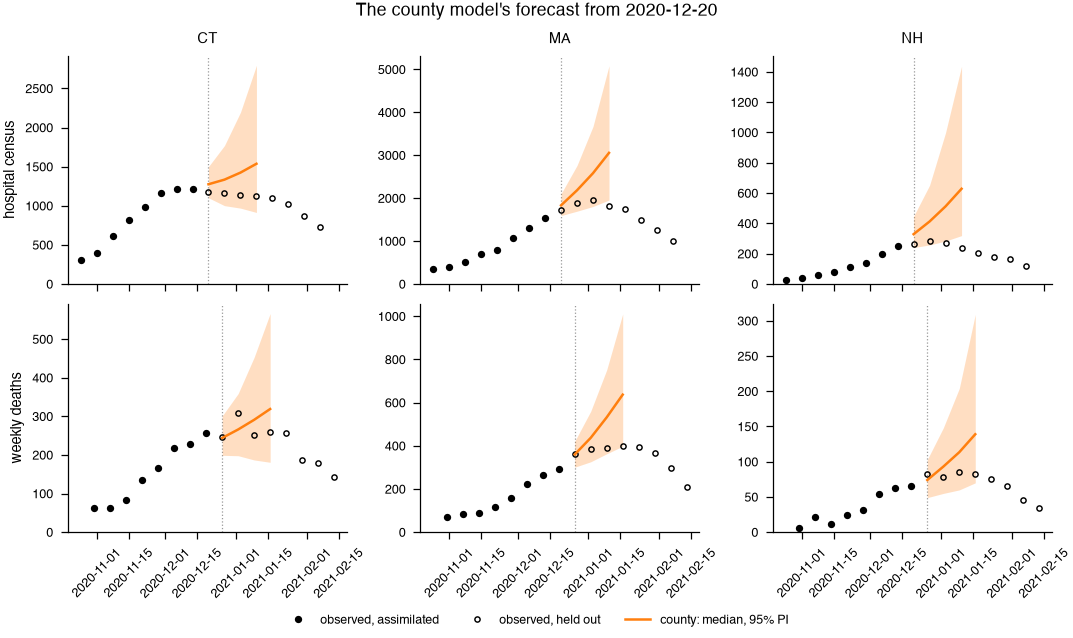

In [12]:
QUANTITIES = ("census", "deaths")
YLABELS = ("hospital census", "weekly deaths")
STATE_NAMES = [state_scope.labels[i] for i in range(state_scope.nodes)]
WINDOW = slice(origin_week - 8, origin_week + HORIZON_WEEKS + 4)  # what to draw


def panels(forecasts):
    # One row per quantity, one column per state.
    rows = []
    for q, (series, dates) in enumerate((
        (state_census, observed.census_dates),
        (state_deaths, observed.death_dates),
    )):
        row = []
        for s, name in enumerate(STATE_NAMES):
            row.append({
                "title": name if q == 0 else None,
                "dates": dates[WINDOW],
                "observed": series[WINDOW, s],
                "origin": dates[origin_week],
                "forecast_dates": dates[origin_week:origin_week + HORIZON_WEEKS],
                "forecasts": {
                    label: {level: values[:, s, q] for level, values in result.items()}
                    for label, result in forecasts.items()
                },
            })
        rows.append(row)
    return rows


fig, _ = plot_single_forecast_grid(
    panels({"county": county_states}), colors=COLORS, ylabels=YLABELS,
    title=f"The county model's forecast from {observed.census_dates[origin_week]}",
)
plt.show()

## 8. The other two models: one change each

The comparison rests on the models differing only in what the question is about, so each
of the other two is the `county` model with one thing changed.

**`movement`** adds commuting. `mm.Pei()` moves commuters to their work county and back
twice a day, using the ACS commuting matrix fetched above. Everything else is identical,
down to the parameters, priors and initial conditions.

In [13]:
movement_model = SingleStrataRUME.build(
    ipm=SEIRHD(),
    mm=mm.Pei(),  # was mm.No()
    init=Explicit(initials=np.zeros((county_scope.nodes, 6), dtype=np.int64)),
    scope=county_scope,
    time_frame=fit_window,
    params={**county_params, "mm::commuters": commuters},  # plus commuting flows
)

**`state`** removes the counties. Each state is one node with the state's population, and
it is fitted to the state totals of the same observations. It needs no county-level data
at all.

In [14]:
state_model = SingleStrataRUME.build(
    ipm=SEIRHD(),
    mm=mm.No(),
    init=Explicit(initials=np.zeros((state_scope.nodes, 6), dtype=np.int64)),
    scope=state_scope,  # was county_scope
    time_frame=fit_window,
    params={**county_params, "*::population": state_population},  # state populations
)

The same three calls fit and forecast both. The movement model takes about three times as
long as the county model: commuting is two movement steps a day, and every step moves
people between all 32 counties.

In [15]:
movement_fit = fit(
    movement_model,
    observations_for(movement_model, covid_season.observation_source(aggregated=False)),
    covid_season.county_initial_values,
)
state_fit = fit(
    state_model,
    observations_for(state_model, covid_season.observation_source(aggregated=True)),
    covid_season.state_initial_values,
)

movement_states = quantiles(to_states(weekly(forecast(movement_fit))))
state_states = quantiles(to_states(weekly(forecast(state_fit))))

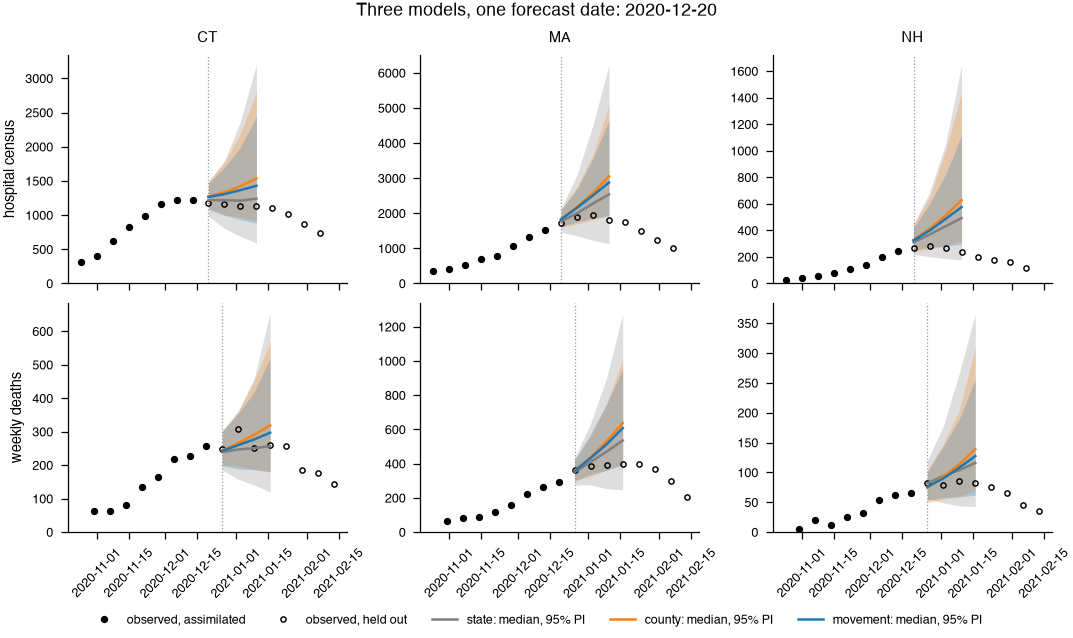

In [16]:
fig, _ = plot_single_forecast_grid(
    panels({"state": state_states, "county": county_states, "movement": movement_states}),
    colors=COLORS, ylabels=YLABELS,
    title=f"Three models, one forecast date: {observed.census_dates[origin_week]}",
)
plt.show()

### What the filter learned

The estimated transmission rate as of each day of the fit, summarized per state. For the
county models it is the population-weighted mean over a state's counties, realization by
realization, then the median across realizations. The filter has no access to anything
but the observations, so this is the model's own account of how transmission changed
through the autumn.

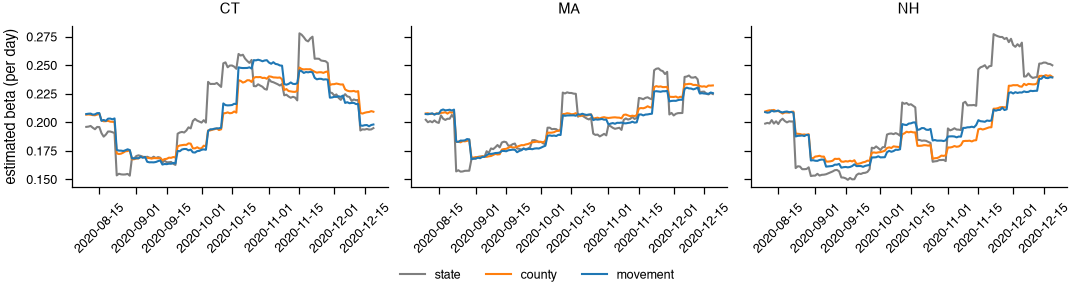

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(7.2, 2.0), sharey=True, layout="constrained")
fit_days = pd.date_range(fit_window.start_date, periods=fit_window.days)
weights = covid_season.to_states() * county_population  # (states, counties)
weights = weights / weights.sum(axis=1, keepdims=True)

for label, fitted in (("state", state_fit), ("county", county_fit),
                      ("movement", movement_fit)):
    key = next(k for k in fitted.estimated_params if str(k).endswith("log_beta"))
    beta = np.exp(fitted.estimated_params[key])  # (realizations, days, nodes)
    if beta.shape[2] != state_scope.nodes:
        beta = np.einsum("sc,rdc->rds", weights, beta)
    for s, ax in enumerate(axs):
        ax.plot(fit_days, np.median(beta[:, :, s], axis=0), color=COLORS[label],
                label=label)
        ax.set_title(STATE_NAMES[s])
        ax.tick_params(axis="x", labelrotation=45)

axs[0].set_ylabel("estimated beta (per day)")
fig.legend(*axs[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
plt.show()

## 9. Is this the model the manuscript ran?

Writing the models out here means there are two copies of each: this notebook's, and the
ones in `manuscript_analysis.demos.covid.models` that produced the manuscript's numbers.
This check builds both over the first two weeks of the season, with the same seed and a
small ensemble, and requires their filter output to be **identical**: every compartment
and every estimated parameter, in every realization. It also requires this notebook's
forecast dynamics to match the module's.

If someone changes one copy and not the other, this cell fails.

In [18]:
import dataclasses

from manuscript_analysis.demos.covid.models import spatial_movement, state_aggregate

CHECK_REALIZATIONS, CHECK_WEEKS = 100, 2
check_window = TimeFrame.of(start_date=season.start_date, duration_days=7 * CHECK_WEEKS)


def short_filter(rume, unknown, observations, initial_values_factory):
    return EnsembleKalmanFilterSimulator(
        config=PipelineConfig.from_rume(
            rume=dataclasses.replace(rume, time_frame=check_window),
            num_realizations=CHECK_REALIZATIONS,
            unknown_params=unknown,
            initial_values=initial_values_factory(
                CHECK_REALIZATIONS, np.random.default_rng(SEED)
            ),
        ),
        observations=observations,
        movement_data_mode="home",
    ).run(rng=np.random.default_rng(SEED))


def same_output(a, b):
    params_a = [a.estimated_params[k] for k in sorted(a.estimated_params, key=str)]
    params_b = [b.estimated_params[k] for k in sorted(b.estimated_params, key=str)]
    return np.array_equal(a.compartments, b.compartments) and all(
        np.array_equal(x, y) for x, y in zip(params_a, params_b, strict=True)
    )


def same_dynamics(a, b):
    return a.keys() == b.keys() and all(
        (a[k].damping, a[k].mean, a[k].standard_deviation)
        == (b[k].damping, b[k].mean, b[k].standard_deviation)
        for k in a
    )


pairs = {
    "county": (county_model, covid_season.county_initial_values, spatial_movement.county,
               False),
    "movement": (movement_model, covid_season.county_initial_values,
                 spatial_movement.movement, False),
    "state": (state_model, covid_season.state_initial_values, state_aggregate.model,
              True),
}
for name, (ours, initial_values_factory, theirs, aggregated) in pairs.items():
    ours_check = dataclasses.replace(ours, time_frame=check_window)
    mine = short_filter(
        ours, unknown_params,
        observations_for(ours_check, covid_season.observation_source(aggregated=aggregated)),
        initial_values_factory,
    )
    module = short_filter(
        theirs.rume, theirs.unknown_params,
        Observations(
            source=theirs.observations_source(),
            model_link=theirs.observations.model_link,
            likelihood=theirs.observations.likelihood,
        ),
        theirs.initial_values_factory,
    )
    assert same_output(mine, module), f"{name}: this notebook's model has drifted"
    assert same_dynamics(forecast_dynamics(mine), theirs.forecast_dynamics(module)), (
        f"{name}: the forecast dynamics have drifted"
    )
    print(f"{name:9s} identical to manuscript_analysis's {theirs.name!r} model")

county    identical to manuscript_analysis's 'county' model


movement  identical to manuscript_analysis's 'movement' model


state     identical to manuscript_analysis's 'state' model
